In [1]:
import os, uuid, hashlib, platform, getpass
# ===== 1. 填写学号 =====
STUDENT_ID = 20244080131 #修改为自己的学号
# ===== 2. 打印 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
# ===== 3. 机器指纹（绑定当前电脑）=====
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
# ===== 4. 生成唯一 ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 20244080131
[机器指纹] 73b9d34140867d67
[RUN_ID] 20244080131-73b9d34140867d67


# 实验1：NumPy 数组、数据类型与索引



In [2]:
import numpy as np

print("NumPy 版本：", np.__version__)

# 1. 不同类型的 ndarray
integer_array = np.array([1, 2, 3], dtype=np.int64)
float_array = np.array([1.5, 2.5, 3.5], dtype=np.float64)
boolean_array = np.array([True, False, True], dtype=np.bool_)

for name, array in (
    ("整数数组", integer_array),
    ("浮点数组", float_array),
    ("布尔数组", boolean_array),
):
    print(f"{name}: {array}, dtype={array.dtype}, shape={array.shape}, ndim={array.ndim}")

# 2. reshape：元素总数保持为 12
sequence = np.arange(12)
array_3x4 = sequence.reshape(3, 4)
array_2x3x2 = sequence.reshape(2, 3, 2)
print("\n原一维数组：\n", sequence)
print("形状 (3, 4)：\n", array_3x4)
print("形状 (2, 3, 2)：\n", array_2x3x2)

# 3. 二维数组索引
second_row = array_3x4[1]
columns_1_to_3 = array_3x4[:, 0:3]
greater_than_6 = array_3x4[array_3x4 > 6]
for name, result in (
    ("第 2 行", second_row),
    ("第 1 至第 3 列", columns_1_to_3),
    ("大于 6 的元素", greater_than_6),
):
    print(f"\n{name}: {result}, shape={result.shape}")

# 4. 组合布尔条件筛选
values = np.arange(10)
less_than_2_or_greater_than_7 = values[(values < 2) | (values > 7)]
greater_than_3_and_less_than_7 = values[(values > 3) & (values < 7)]
print("\n小于 2 或大于 7：", less_than_2_or_greater_than_7)
print("大于 3 且小于 7：", greater_than_3_and_less_than_7)

# 5. 逐元素乘法与矩阵乘法
matrix_a = np.array([[1, 2], [3, 4]])
matrix_b = np.array([[5, 6], [7, 8]])
print("\nA * B：\n", matrix_a * matrix_b)
print("np.multiply(A, B)：\n", np.multiply(matrix_a, matrix_b))
print("A @ B：\n", matrix_a @ matrix_b)
print("np.matmul(A, B)：\n", np.matmul(matrix_a, matrix_b))



NumPy 版本： 2.4.6
整数数组: [1 2 3], dtype=int64, shape=(3,), ndim=1
浮点数组: [1.5 2.5 3.5], dtype=float64, shape=(3,), ndim=1
布尔数组: [ True False  True], dtype=bool, shape=(3,), ndim=1

原一维数组：
 [ 0  1  2  3  4  5  6  7  8  9 10 11]
形状 (3, 4)：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
形状 (2, 3, 2)：
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

第 2 行: [4 5 6 7], shape=(4,)

第 1 至第 3 列: [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]], shape=(3, 3)

大于 6 的元素: [ 7  8  9 10 11], shape=(5,)

小于 2 或大于 7： [0 1 8 9]
大于 3 且小于 7： [4 5 6]

A * B：
 [[ 5 12]
 [21 32]]
np.multiply(A, B)：
 [[ 5 12]
 [21 32]]
A @ B：
 [[19 22]
 [43 50]]
np.matmul(A, B)：
 [[19 22]
 [43 50]]


## 实验结果与说明

1. **dtype、shape 与 ndim**：三个一维数组的 `shape` 均为 `(3,)`，`ndim` 均为 `1`，dtype 分别表示整数、浮点数和布尔值。NumPy 数组通常要求元素具有统一的数据类型，因此便于连续存储并进行高效的向量化运算；Python 列表可以混合不同类型的对象，更灵活，但数值运算通常需要逐项处理。具体整数位宽会受显式 `dtype` 和平台影响。
2. **改变形状**：`np.arange(12)` 含 12 个元素；形状 `(3, 4)` 和 `(2, 3, 2)` 的维度乘积都是 12。reshape 不增删元素，因此新形状各维度乘积必须等于原数组元素总数。
3. **索引结果**：Python 索引从 0 开始，所以 `array_3x4[1]` 是第 2 行，形状为 `(4,)`；`[:, 0:3]` 取第 1 到第 3 列（切片右端不包含），形状为 `(3, 3)`；布尔掩码 `array_3x4 > 6` 取出 `[7, 8, 9, 10, 11]`，结果是一维数组，形状为 `(5,)`。
4. **条件筛选**：对 NumPy 布尔条件使用逐元素逻辑运算符时要加括号。`(values < 2) | (values > 7)` 结果为 `[0, 1, 8, 9]`；`(values > 3) & (values < 7)` 结果为 `[4, 5, 6]`。也可以使用 `np.logical_or` 和 `np.logical_and`。
5. **两种乘法**：`*` 和 `np.multiply` 是逐位置相乘，本例结果为 `[[5, 12], [21, 32]]`。`@` 和 `np.matmul` 是矩阵乘法，本例按行与列做点积，结果为 `[[19, 22], [43, 50]]`。因此 `*` 不会对矩阵行列求和，而 `@` 遵循矩阵乘法的维度规则。

# 实验2：随机抽样、统计与缺失值

成绩样本统计（裁剪后）
样本数：1000
最小值：32.53
最大值：100.00
均值：70.21
标准差：10.29
极差：67.47

均匀无放回抽样： [10  6  4  5  2]
按数值成比例加权的无放回抽样： [ 8  9 10  7  2]

permutation 前的原数组： [ 1  2  3  4  5  6  7  8  9 10]
permutation 返回的新数组： [10  5  6  2  7  8  4  1  3  9]
permutation 后的原数组： [ 1  2  3  4  5  6  7  8  9 10]
shuffle 前的数组副本： [ 1  2  3  4  5  6  7  8  9 10]
shuffle 原地打乱后的数组： [ 1  9  8  7 10  6  2  3  4  5]

加入缺失值后的统计
缺失值个数：3
普通均值 np.mean：nan
忽略缺失值的均值 np.nanmean：70.22

scores_df 前 5 行：
   序号         成绩
0   1  62.068775
1   2  72.405713
2   3  51.036737
3   4  83.957717
4   5  76.382947
含缺失值的记录：
    序号  成绩
9   10 NaN
19  20 NaN
29  30 NaN
scores_df shape： (1000, 2)


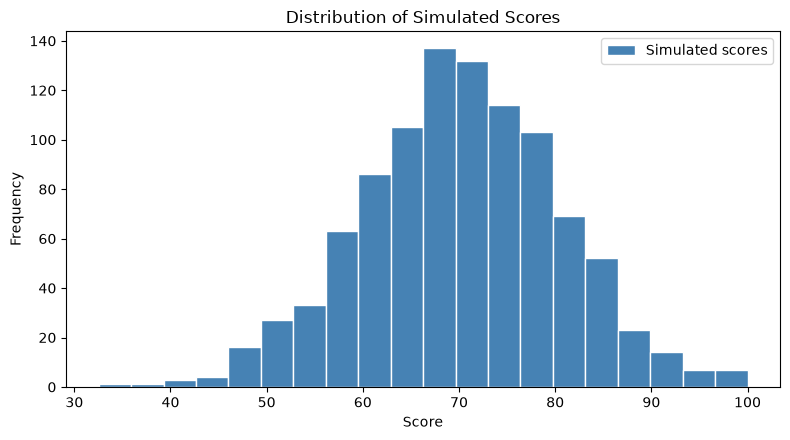


全部断言通过；scores_df 已保留在内存中，未写入磁盘。


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 固定种子，确保本实验可复现
rng = np.random.default_rng(2026)

# 1. 模拟 1,000 个成绩并限制在 0 到 100
raw_scores = rng.normal(loc=70, scale=10, size=1000)
simulated_scores = np.clip(raw_scores, 0, 100)
score_count = simulated_scores.size
score_min = simulated_scores.min()
score_max = simulated_scores.max()
score_mean = simulated_scores.mean()
score_std = simulated_scores.std()
score_range = np.ptp(simulated_scores)

print("成绩样本统计（裁剪后）")
print(f"样本数：{score_count}")
print(f"最小值：{score_min:.2f}")
print(f"最大值：{score_max:.2f}")
print(f"均值：{score_mean:.2f}")
print(f"标准差：{score_std:.2f}")
print(f"极差：{score_range:.2f}")

# 2. 从 1 到 10 无放回抽取 5 个整数
population = np.arange(1, 11)
uniform_sample = rng.choice(population, size=5, replace=False)
weights = population / population.sum()
weighted_sample = rng.choice(population, size=5, replace=False, p=weights)
print("\n均匀无放回抽样：", uniform_sample)
print("按数值成比例加权的无放回抽样：", weighted_sample)

# 3. permutation 返回新数组；shuffle 原地改变副本
original_for_permutation = np.arange(1, 11)
permuted_values = rng.permutation(original_for_permutation)
print("\npermutation 前的原数组：", original_for_permutation)
print("permutation 返回的新数组：", permuted_values)
print("permutation 后的原数组：", original_for_permutation)

array_to_shuffle = np.arange(1, 11)
shuffle_before = array_to_shuffle.copy()
rng.shuffle(array_to_shuffle)
print("shuffle 前的数组副本：", shuffle_before)
print("shuffle 原地打乱后的数组：", array_to_shuffle)

# 4. 将第 10、20、30 个成绩设为缺失值
scores_with_missing = simulated_scores.copy()
missing_positions = np.array([9, 19, 29])
scores_with_missing[missing_positions] = np.nan
missing_count = np.isnan(scores_with_missing).sum()
ordinary_mean = np.mean(scores_with_missing)
nan_aware_mean = np.nanmean(scores_with_missing)
print("\n加入缺失值后的统计")
print(f"缺失值个数：{missing_count}")
print(f"普通均值 np.mean：{ordinary_mean}")
print(f"忽略缺失值的均值 np.nanmean：{nan_aware_mean:.2f}")

# 5. 保存在内存中的 DataFrame，实验 4 可直接使用 scores_df
scores_df = pd.DataFrame({
    "序号": np.arange(1, score_count + 1),
    "成绩": scores_with_missing,
})
print("\nscores_df 前 5 行：")
print(scores_df.head())
print("含缺失值的记录：")
print(scores_df.loc[scores_df["成绩"].isna()])
print("scores_df shape：", scores_df.shape)

# 分布图：使用非缺失成绩绘制，并标注标题、坐标轴和图例
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(scores_df["成绩"].dropna(), bins=20, color="steelblue", edgecolor="white", label="Simulated scores")
ax.set_title("Distribution of Simulated Scores")
ax.set_xlabel("Score")
ax.set_ylabel("Frequency")
ax.legend()
fig.tight_layout()
plt.show()

# 验证统计、无放回抽样、打乱方式、缺失值和内存表格
assert score_count == 1000
assert 0 <= score_min <= score_max <= 100
assert uniform_sample.size == weighted_sample.size == 5
assert np.unique(uniform_sample).size == np.unique(weighted_sample).size == 5
assert np.array_equal(original_for_permutation, np.arange(1, 11))
assert np.array_equal(np.sort(array_to_shuffle), np.arange(1, 11))
assert missing_count == 3 and np.isnan(ordinary_mean)
assert np.isclose(nan_aware_mean, np.mean(simulated_scores[np.isfinite(scores_with_missing)]))
assert scores_df.shape == (1000, 2)
assert scores_df["成绩"].isna().sum() == 3
print("\n全部断言通过；scores_df 已保留在内存中，未写入磁盘。")

## 实验结果与说明

1. **模拟成绩**：使用固定种子 `2026` 从均值 70、标准差 10 的正态分布抽取 1,000 个值，再用 `np.clip` 将成绩限制在 0 到 100。运行结果约为：最小值 32.53、最大值 100.00、均值 70.21、标准差 10.29、极差 67.47。最大值达到 100 是超出上界的样本被裁剪的结果；图表展示裁剪后成绩的分布。
2. **无放回抽样**：`rng.choice(population, size=5, replace=False)` 对总体中的每个整数等概率抽样。加权版本增加 `p=weights`，其中 `weights = population / population.sum()`，所以数值越大的整数被抽中的概率越高；`replace=False` 仍保证每个结果最多出现一次。固定随机种子使结果可复现。
3. **随机排列**：`rng.permutation(array)` 返回打乱后的新数组，原数组保持不变；`rng.shuffle(array)` 直接原地修改传入数组。代码先复制原数组用于展示和验证。
4. **缺失值统计**：将第 10、20、30 个成绩（Python 下标 9、19、29）设为 `np.nan` 后，`np.mean` 的结果是 `nan`，因为普通均值传播缺失值；`np.nanmean` 会忽略缺失项，本次结果约为 70.22。`np.isnan` 统计出 3 个缺失值。
5. **供实验 4 使用的数据**：`scores_df` 是当前内核中的 pandas DataFrame，包含 `序号` 和 `成绩` 两列、共 1,000 行；三个缺失成绩保留为 `NaN`。变量仅保存在内存中，没有写入磁盘。后续实验可直接引用 `scores_df`，无需重新生成数据。

# 实验3：Scipy数值计算与Matplotlib可视化

线性方程组解 [x, y]： [2. 3.]
代回左侧： [9. 8.]

正根求解成功： True
正根： 1.4142135623730947 函数值： -8.881784197001252e-16
负根求解成功： True
负根： -1.4142135623730947 函数值： -8.881784197001252e-16

最优化成功： True
数值极小点： -0.5000000064345924
数值最小值： 1.75
解析极小点与最小值： -0.5 1.75

独立样本 t 检验（双侧，等方差）
第一组样本均值：0.0438
第二组样本均值：1.1852
t 统计量：-8.3450
p 值：1.2078e-14
显著性水平：0.05
判断：拒绝两组总体均值相等的原假设


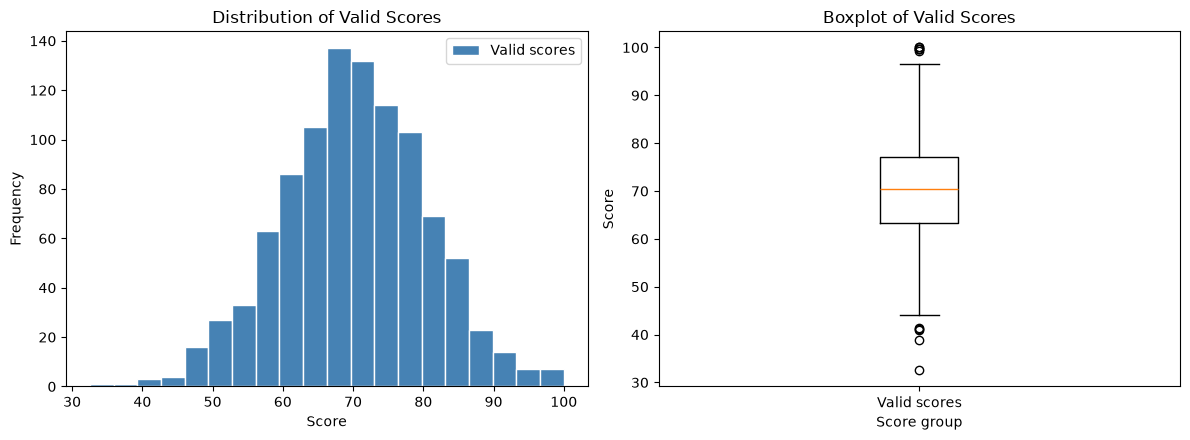

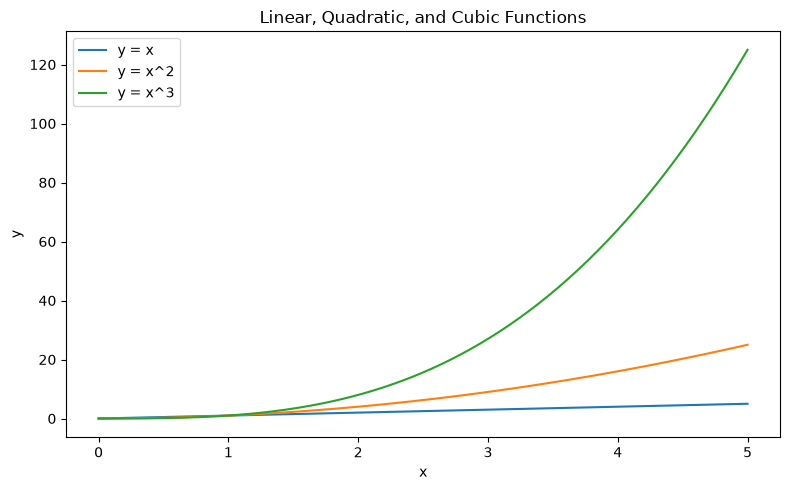


实验3全部数值断言通过。


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg, optimize, stats

# 1. 解线性方程组：3x + y = 9，x + 2y = 8
coefficients = np.array([[3, 1], [1, 2]], dtype=float)
constants = np.array([9, 8], dtype=float)
linear_solution = linalg.solve(coefficients, constants)
print("线性方程组解 [x, y]：", linear_solution)
print("代回左侧：", coefficients @ linear_solution)

# 2. 使用不同初始猜测求 x^2 - 2 = 0 的正根和负根
root_function = lambda value: value**2 - 2
positive_root_result = optimize.root(root_function, x0=1.0)
negative_root_result = optimize.root(root_function, x0=-1.0)
print("\n正根求解成功：", positive_root_result.success)
print("正根：", positive_root_result.x[0], "函数值：", root_function(positive_root_result.x[0]))
print("负根求解成功：", negative_root_result.success)
print("负根：", negative_root_result.x[0], "函数值：", root_function(negative_root_result.x[0]))

# 3. 数值最小化 f(x) = x^2 + x + 2
objective = lambda value: value**2 + value + 2
minimum_result = optimize.minimize(objective, x0=0.0)
analytical_x = -0.5
analytical_value = analytical_x**2 + analytical_x + 2
print("\n最优化成功：", minimum_result.success)
print("数值极小点：", minimum_result.x[0])
print("数值最小值：", minimum_result.fun)
print("解析极小点与最小值：", analytical_x, analytical_value)

# 4. 固定种子生成两组独立正态样本并进行独立样本 t 检验
rng_exp3 = np.random.default_rng(202603)
sample_a = rng_exp3.normal(loc=0, scale=1, size=100)
sample_b = rng_exp3.normal(loc=1, scale=1, size=100)
test_result = stats.ttest_ind(sample_a, sample_b, equal_var=True)
significance_level = 0.05
reject_equal_means = test_result.pvalue < significance_level
print("\n独立样本 t 检验（双侧，等方差）")
print(f"第一组样本均值：{sample_a.mean():.4f}")
print(f"第二组样本均值：{sample_b.mean():.4f}")
print(f"t 统计量：{test_result.statistic:.4f}")
print(f"p 值：{test_result.pvalue:.6g}")
print(f"显著性水平：{significance_level}")
print("判断：拒绝两组总体均值相等的原假设" if reject_equal_means else "判断：未能拒绝两组总体均值相等的原假设")

# 5a. 绘制实验2中的有效成绩直方图和箱线图
valid_scores = scores_df["成绩"].dropna().to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(valid_scores, bins=20, color="steelblue", edgecolor="white", label="Valid scores")
axes[0].set_title("Distribution of Valid Scores")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[1].boxplot(valid_scores, tick_labels=["Valid scores"])
axes[1].set_title("Boxplot of Valid Scores")
axes[1].set_xlabel("Score group")
axes[1].set_ylabel("Score")
fig.tight_layout()
plt.show()

# 5b. 在同一坐标系中绘制 y=x、y=x^2、y=x^3
x_values = np.linspace(0, 5, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_values, x_values, label="y = x")
ax.plot(x_values, x_values**2, label="y = x^2")
ax.plot(x_values, x_values**3, label="y = x^3")
ax.set_title("Linear, Quadratic, and Cubic Functions")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
fig.tight_layout()
plt.show()

# 核对解析结果、根和检验数据
assert np.allclose(coefficients @ linear_solution, constants)
assert positive_root_result.success and np.isclose(positive_root_result.x[0], np.sqrt(2))
assert negative_root_result.success and np.isclose(negative_root_result.x[0], -np.sqrt(2))
assert np.isclose(root_function(positive_root_result.x[0]), 0, atol=1e-8)
assert minimum_result.success and np.isclose(minimum_result.x[0], analytical_x, atol=1e-5)
assert np.isclose(minimum_result.fun, analytical_value, atol=1e-5)
assert sample_a.size == sample_b.size == 100
assert test_result.pvalue >= 0 and test_result.pvalue <= 1
assert valid_scores.size == 997
print("\n实验3全部数值断言通过。")

## 实验结果与说明

1. **线性方程组**：`scipy.linalg.solve` 得到 $x=2$、$y=3$；将解代回系数矩阵后得到 `[9, 8]`，与方程右侧一致。
2. **方程求根**：对 $f(x)=x^2-2$ 分别使用正、负初始猜测调用 `scipy.optimize.root`，都成功收敛。结果约为 $\sqrt{2}=1.4142$ 和 $-\sqrt{2}=-1.4142$，代回函数后的残差接近 0。初始猜测决定迭代更可能收敛到哪个根。
3. **函数最小值**：`scipy.optimize.minimize` 得到极小点约为 $x=-0.5$，函数值为 $1.75$。解析结果来自 $f'(x)=2x+1=0$，与数值结果一致。
4. **独立样本 t 检验**：固定种子 `202603` 生成两组各 100 个观测值，并进行双侧、等方差独立样本 t 检验。本次 $t\approx -8.345$、$p\approx 1.21\times10^{-14}<0.05$，因此在 0.05 显著性水平下拒绝“两组总体均值相等”的原假设。负的 t 值表示本次样本中第一组均值低于第二组；检验结论针对总体均值差异。
5. **图表**：前两幅子图是实验2中 997 个非缺失成绩的直方图和箱线图；第三幅图在同一坐标系比较 $y=x$、$y=x^2$、$y=x^3$（$0\le x\le5$）。每幅图均包含标题、坐标轴标签；需要区分数据系列的图包含图例。图像直接显示在 Notebook 中，不保存到文件。

# 实验4：pandas Series、DataFrame与内存中的CSV读写

In [14]:
import io
import pandas as pd

# 题目给定的学生成绩数据
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

# 1. 建立以姓名為索引的 DataFrame，計算 Total 和 Average
students_df = pd.DataFrame(records).set_index("Name")
subject_columns = ["Math", "English", "Python"]
students_df["Total"] = students_df[subject_columns].sum(axis=1)
students_df["Average"] = students_df[subject_columns].mean(axis=1)
print("索引：", students_df.index.tolist())
print("列名：", students_df.columns.tolist())
print("前 3 行：")
print(students_df.head(3))
print("基本统计信息：")
print(students_df[subject_columns + ["Total", "Average"]].describe())

# 2. 用 loc 和 iloc 查找 Carol，并筛选平均分不低于 80 的学生
carol_by_label = students_df.loc["Carol"]
carol_by_position = students_df.iloc[2]
high_average_students = students_df.loc[students_df["Average"] >= 80]
print("\nloc 查询 Carol：\n", carol_by_label)
print("iloc 查询第 3 条记录（Carol）：\n", carol_by_position)
print("平均分不低于 80 的学生：\n", high_average_students)

# 3. 按列和按行计算三科均值
subject_means = students_df[subject_columns].mean(axis=0)
student_means = students_df[subject_columns].mean(axis=1)
print("\n每科平均分：\n", subject_means)
print("每名学生三科平均分：\n", student_means)

# 4. apply 计算每人最高分；agg 汇总每科；rank 排名
students_df["Highest"] = students_df[subject_columns].apply(max, axis=1)
subject_summary = students_df[subject_columns].agg(["min", "mean", "max"])
students_df["Rank"] = students_df["Average"].rank(ascending=False, method="min").astype(int)
print("\n每名学生最高分：\n", students_df["Highest"])
print("每科最小值、均值和最大值：\n", subject_summary)
print("按平均分排名：\n", students_df[["Average", "Rank"]].sort_values("Rank"))

# 5. 按组统计人数和各科平均分；transform 将组内 Python 均值映射回每行
group_summary = students_df.groupby("Group")[subject_columns].agg(["size", "mean"])
students_df["Group_Python_Mean"] = students_df.groupby("Group")["Python"].transform("mean")
print("\n各组人数及三科平均分：\n", group_summary)
print("每名学生对应的组内 Python 平均分：\n", students_df[["Group", "Python", "Group_Python_Mean"]])

# 6. 保留 Python 平均分不低于 80 的组
qualified_groups = students_df.groupby("Group").filter(lambda group: group["Python"].mean() >= 80)
print("\nPython 组平均分不低于 80 的学生：\n", qualified_groups[["Group", *subject_columns, "Group_Python_Mean"]])
print("符合条件的组：", qualified_groups["Group"].unique().tolist())

# 7. 计算三科协方差与相关系数矩阵
covariance_matrix = students_df[subject_columns].cov()
correlation_matrix = students_df[subject_columns].corr()
print("\n三科协方差矩阵：\n", covariance_matrix)
print("三科相关系数矩阵：\n", correlation_matrix)
print("Math 与 Python：协方差 =", covariance_matrix.loc["Math", "Python"],
      ", 相关系数 =", correlation_matrix.loc["Math", "Python"])

# CSV 在内存中往返读写，不创建磁盘文件
csv_buffer = io.StringIO()
students_df.to_csv(csv_buffer, index=True, index_label="Name")
csv_buffer.seek(0)
students_from_csv = pd.read_csv(csv_buffer, index_col="Name")
print("\n从内存 CSV 读取的前 3 行：\n", students_from_csv.head(3))

# 核对关键结果
assert students_df.index.name == "Name"
assert students_df.loc["Carol", "Total"] == 265
assert students_df.loc["Carol", "Average"] == 265 / 3
assert carol_by_label.equals(carol_by_position)
assert high_average_students.index.tolist() == ["Alice", "Carol", "Eva", "Frank"]
assert qualified_groups["Group"].unique().tolist() == ["A", "B"]
assert students_df["Group_Python_Mean"].notna().all()
assert students_from_csv.index.tolist() == students_df.index.tolist()
assert students_from_csv[subject_columns].equals(students_df[subject_columns])
assert correlation_matrix.shape == covariance_matrix.shape == (3, 3)
print("\n实验4全部断言通过；CSV 仅在内存中处理。")

索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前 3 行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

loc 查询 Carol：
 Group              B
Math   

## 实验结果与说明

1. **DataFrame 与统计**：`students_df` 以 `Name` 为行索引，包含 `Group`、三科成绩、`Total`（三科总分）和 `Average`（三科平均分）。`describe()` 汇总数值列的计数、均值、标准差、分位数、最小值和最大值；例如 Math 均值约为 79.83，Python 均值约为 83.67。
2. **标签索引和位置索引**：`.loc["Carol"]` 按姓名标签查找；`.iloc[2]` 按从 0 开始的位置取第 3 行，二者都返回 Carol。按 `Average >= 80` 筛选得到 Alice、Carol、Eva、Frank。
3. **axis 的含义**：`mean(axis=0)` 沿行方向汇总，得到每科的列均值；`mean(axis=1)` 沿列方向汇总，得到每名学生的行均值。当前每科均值依次为 Math 79.83、English 80.83、Python 83.67。
4. **apply、agg 与 rank**：`apply(max, axis=1)` 逐行计算每名学生的最高科目分；`agg(["min", "mean", "max"])` 一次汇总每科的最小值、均值和最大值；`rank(ascending=False)` 按平均分从高到低排名，最高平均分排名为 1。
5. **分组统计**：`groupby("Group").agg(...)` 计算各组人数及科目平均分；`transform("mean")` 将本组 Python 平均分广播回该组每名学生所在的行。A 组 Python 均值为 87.00，B 组为 80.33，因此 `filter()` 中“不低于 80”的条件保留了 A、B 两组全部学生。
6. **协方差和相关系数**：协方差为正，表示两科成绩总体上倾向于同向变化，但数值受成绩尺度影响；相关系数是标准化后的线性关系指标，范围为 -1 到 1。Math 与 Python 的协方差约为 74.93、相关系数约为 0.885，表示这组数据中二者呈较强正线性相关；相关不代表因果。
7. **内存 CSV**：代码使用 `io.StringIO` 将 DataFrame 写入内存字符串缓冲区，再用 `read_csv` 读回，并验证索引及成绩数据一致。整个过程没有创建或写入磁盘文件。